## Import the important libraries & check their versions

In [219]:
import numpy as np
import pandas as pn
import matplotlib
import matplotlib.pyplot as plt
print(np.__version__)
print(pn.__version__)
print(matplotlib.__version__)

2.4.4
3.0.2
3.10.8


## import the Dataset & Explore it

In [220]:
ds = pn.read_csv('E:\Datasets\Student_performance_data _\Student_performance_data _.csv')
print(ds.shape)
print('-'*100)
print(ds.columns)
print('-'*100)
print(ds.dtypes)

(2392, 15)
----------------------------------------------------------------------------------------------------
Index(['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation',
       'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport',
       'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA',
       'GradeClass'],
      dtype='str')
----------------------------------------------------------------------------------------------------
StudentID              int64
Age                    int64
Gender                 int64
Ethnicity              int64
ParentalEducation      int64
StudyTimeWeekly      float64
Absences               int64
Tutoring               int64
ParentalSupport        int64
Extracurricular        int64
Sports                 int64
Music                  int64
Volunteering           int64
GPA                  float64
GradeClass           float64
dtype: object


In [221]:
print(ds.head())
print('-'*100)
print(ds.tail())

   StudentID  Age  Gender  Ethnicity  ParentalEducation  StudyTimeWeekly  \
0       1001   17       1          0                  2        19.833723   
1       1002   18       0          0                  1        15.408756   
2       1003   15       0          2                  3         4.210570   
3       1004   17       1          0                  3        10.028829   
4       1005   17       1          0                  2         4.672495   

   Absences  Tutoring  ParentalSupport  Extracurricular  Sports  Music  \
0         7         1                2                0       0      1   
1         0         0                1                0       0      0   
2        26         0                2                0       0      0   
3        14         0                3                1       0      0   
4        17         1                3                0       0      0   

   Volunteering       GPA  GradeClass  
0             0  2.929196         2.0  
1             0  3

In [222]:
print(ds.info())
print('-'*100)
print(ds.describe())

<class 'pandas.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB
None
------------------------------

In [223]:
null_rows = ds[ds.isnull().any(axis=1)]
print(null_rows)

Empty DataFrame
Columns: [StudentID, Age, Gender, Ethnicity, ParentalEducation, StudyTimeWeekly, Absences, Tutoring, ParentalSupport, Extracurricular, Sports, Music, Volunteering, GPA, GradeClass]
Index: []


In [224]:
duplicated_rows = ds[ds.duplicated()]
print(duplicated_rows)

Empty DataFrame
Columns: [StudentID, Age, Gender, Ethnicity, ParentalEducation, StudyTimeWeekly, Absences, Tutoring, ParentalSupport, Extracurricular, Sports, Music, Volunteering, GPA, GradeClass]
Index: []


## clean dataset

### clean GradeClass

In [225]:
unclean_data = ds[(ds['GPA'] >= 3.5) & (ds['GradeClass'] != 0.0)]
print(unclean_data[['GPA', 'GradeClass']])

           GPA  GradeClass
2183  3.545153         2.0
2295  3.597766         2.0
2319  4.000000         3.0
2326  3.546433         1.0
2338  3.572945         1.0
2354  3.979421         4.0


In [226]:
conditions = [
    ds['GPA'] >= 3.5,
    (ds['GPA'] >= 3.0) & (ds['GPA'] < 3.5),
    (ds['GPA'] >= 2.5) & (ds['GPA'] < 3.0),
    (ds['GPA'] >= 2.0) & (ds['GPA'] < 2.5),
    ds['GPA'] < 2.0
]
choices = [0.0, 1.0, 2.0, 3.0, 4.0]
ds['GradeClass'] = np.select(conditions, choices)

In [227]:
unclean_data = ds[(ds['GPA'] >= 3.5) & (ds['GradeClass'] != 0.0)]
print(unclean_data[['GPA', 'GradeClass']])

Empty DataFrame
Columns: [GPA, GradeClass]
Index: []


## explore each column

In [228]:
print(ds.columns[(ds.dtypes == np.int64) | (ds.dtypes == np.float64)])

Index(['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation',
       'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport',
       'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA',
       'GradeClass'],
      dtype='str')


### Gender

Gender
0    1170
1    1222
Name: Gender, dtype: int64


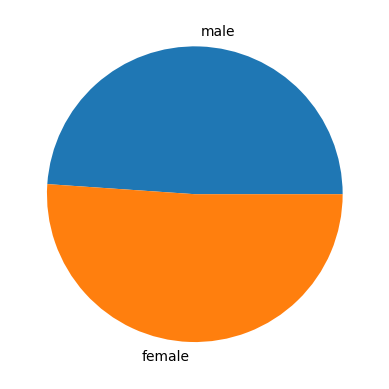

In [425]:
genders = ds.groupby('Gender')['Gender'].count()
print(genders)
genders.index = ['male', 'female']
plt.pie(genders, labels=genders.index)
plt.show()

### Ethnicity

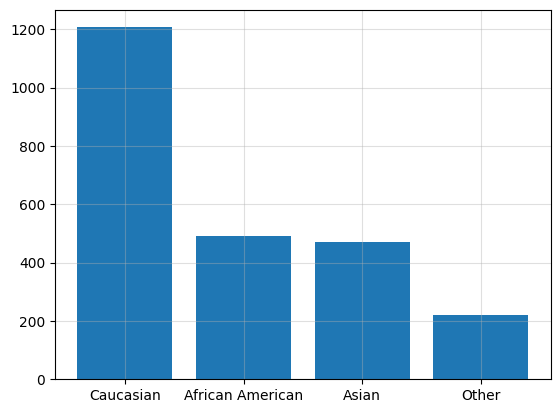

In [423]:
ethnicities = ds.groupby('Ethnicity')['Ethnicity'].count()
ethnicities.index = ['Caucasian', 'African American', 'Asian', 'Other']
plt.grid(alpha = 0.4)
plt.bar(ethnicities.index, ethnicities)
plt.show()

### ParentalEducation

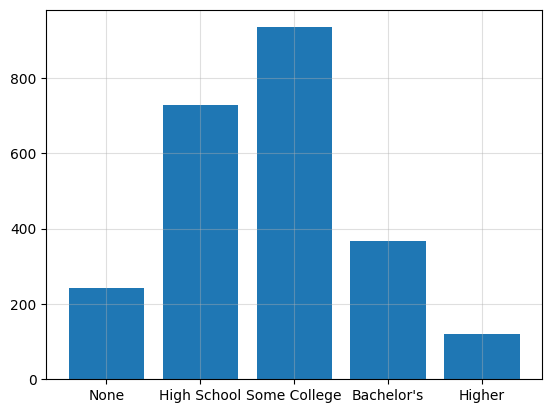

In [416]:
parentalEducation = ds.groupby('ParentalEducation')['ParentalEducation'].count()
parentalEducation.index = ['None', 'High School', 'Some College', "Bachelor's", 'Higher']
plt.grid(alpha = 0.4)
plt.bar(parentalEducation.index, parentalEducation)
plt.show()

## ParentalSupport

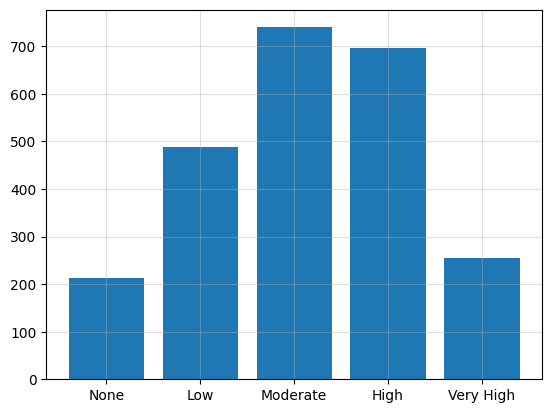

In [417]:
parentalSupport = ds.groupby('ParentalSupport')['ParentalSupport'].count()
parentalSupport.index = ['None', 'Low', 'Moderate', 'High', 'Very High']
plt.grid(alpha = 0.4)
plt.bar(parentalSupport.index, parentalSupport.values)
plt.show()

## Analysis

### Dataset Overview
- How many students are in the dataset?
- How many features (columns) are there?
- Are there any missing values?
- Are there duplicated records?
- What are the data types of each column?
- What is the average GPA?
- What is the GPA distribution?

2392
----------------------------------------------------------------------------------------------------
15
----------------------------------------------------------------------------------------------------
No
----------------------------------------------------------------------------------------------------
No
----------------------------------------------------------------------------------------------------
StudentID              int64
Age                    int64
Gender                 int64
Ethnicity              int64
ParentalEducation      int64
StudyTimeWeekly      float64
Absences               int64
Tutoring               int64
ParentalSupport        int64
Extracurricular        int64
Sports                 int64
Music                  int64
Volunteering           int64
GPA                  float64
GradeClass           float64
dtype: object
----------------------------------------------------------------------------------------------------
1.9061863027265407
-------------

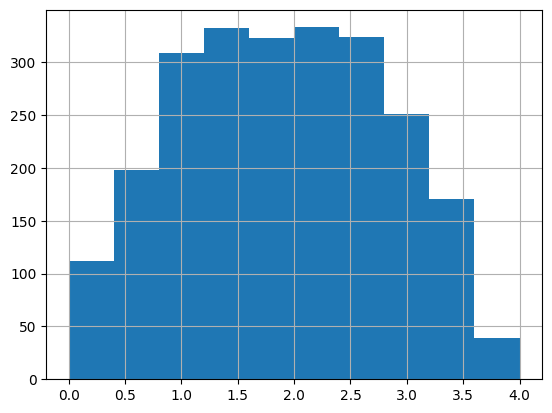

In [342]:
print(ds.shape[0])

print('-'*100)

print(ds.shape[1])

print('-'*100)

missingValues = ds.isnull().any(axis = 1)
answer = 'No' if missingValue.sum() == 0 else 'Yes'
print(answer)

print('-'*100)

duplicatedRecords = ds.duplicated()
answer = 'No' if duplicatedRecords.sum() == 0 else 'Yes'
print(answer)

print('-'*100)

print(ds.dtypes)

print('-'*100)

print(ds['GPA'].mean())

print('-'*100)

print(ds['GPA'].std())

#A distribution is essentially a breakdown of how many elements (or data points) fall into different ranges or categories.
ds['GPA'].hist()
plt.show()

### Student Demographics
- How many male and female students are there?
- What is the age distribution?
- Which ethnicity has the most students?
- What is the most common parental education level?

1170 1222
----------------------------------------------------------------------------------------------------


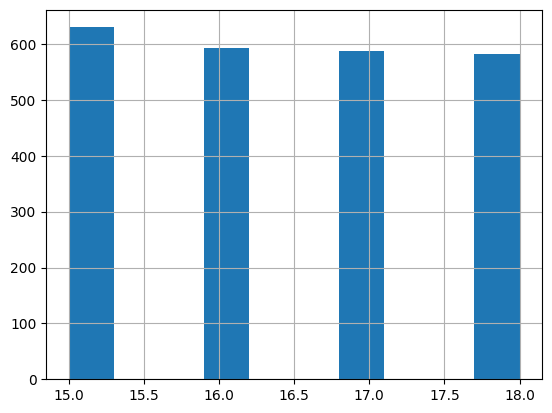

----------------------------------------------------------------------------------------------------
Caucasian 1207
----------------------------------------------------------------------------------------------------
Some College 934


In [428]:
males = ds[ds['Gender'] == 0]['Gender'].count()
females = ds[ds['Gender'] == 1]['Gender'].count()
genders = {'Male': males, 'Female':females}
print(genders['Male'], genders['Female'])

print('-'*100)

ds['Age'].hist()
plt.show()

print('-'*100)


ethnicities = ds.groupby('Ethnicity')['Ethnicity'].count()
ethnicities.index = ['Caucasian', 'African American', 'Asian', 'Other']
print(ethnicities.idxmax(), ethnicities.max())

print('-'*100)

parentalEducations = ds.groupby('ParentalEducation')['ParentalEducation'].count()
parentalEducations.index = ['None', 'High School', 'Some College', "Bachelor's", 'Higher']
print(parentalEducations.idxmax(), parentalEducations.max())

### GPA Analysis
- What is the average GPA?
- What is the highest GPA?
- What is the lowest GPA?
- What is the median GPA?
- What is the standard deviation of GPA?
- How many students have a GPA above 3.5?

In [471]:
print(ds['GPA'].mean())
print('-'*100)
print(ds['GPA'].max())
print('-'*100)
print(ds['GPA'].min())
print('-'*100)
print(ds['GPA'].median())
print('-'*100)
print(ds['GPA'].std())
print('-'*100)
students = ds[ds['GPA'] > 3.5]
print(students.shape[0])

1.9061863027265407
----------------------------------------------------------------------------------------------------
4.0
----------------------------------------------------------------------------------------------------
0.0
----------------------------------------------------------------------------------------------------
1.8933926937866847
----------------------------------------------------------------------------------------------------
0.91515582032496
----------------------------------------------------------------------------------------------------
77


### Study Habits
- What is the average weekly study time?
- Do students who study more have higher GPAs?
- What is the relationship between study time and GPA?
- What is the average study time for A students?
- What is the average study time for F students?

9.771991919431738
----------------------------------------------------------------------------------------------------


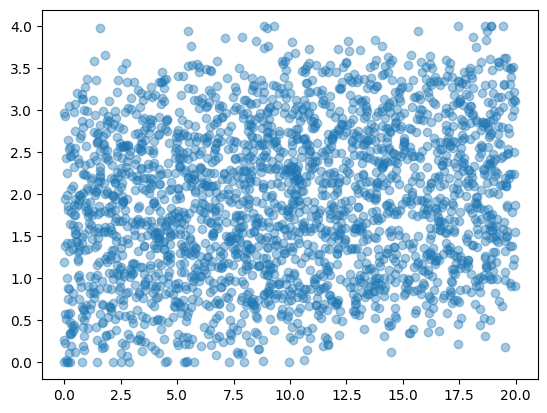

----------------------------------------------------------------------------------------------------
0.17927512685608818
----------------------------------------------------------------------------------------------------
12.891883686639195
----------------------------------------------------------------------------------------------------
9.13870733906467
----------------------------------------------------------------------------------------------------


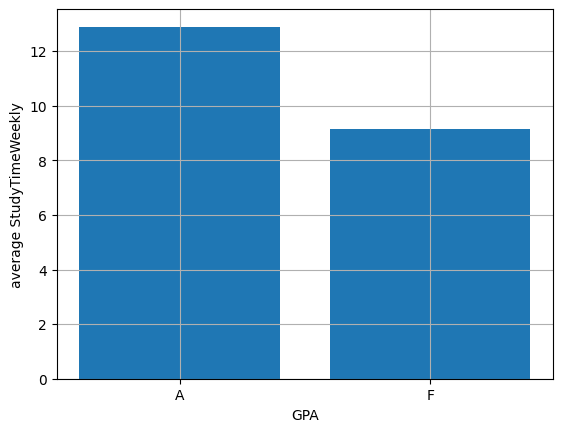

In [480]:
print(ds['StudyTimeWeekly'].mean())
print('-'*100)
plt.scatter(ds['StudyTimeWeekly'], ds['GPA'], alpha=0.4)
plt.show()
print('-'*100)
correlation = ds['StudyTimeWeekly'].corr(ds['GPA'])
print(correlation)
print('-'*100)
StudyTimeWeekly_A = ds[ds['GPA'] >= 3.5]['StudyTimeWeekly']
average_StudyTimeWeekly_A = StudyTimeWeekly_A.mean()
print(average_StudyTimeWeekly_A)
print('-'*100)
StudyTimeWeekly_F = ds[ds['GPA'] < 2]['StudyTimeWeekly']
average_StudyTimeWeekly_F = StudyTimeWeekly_F.mean()
print(average_StudyTimeWeekly_F)
print('-'*100)
plt.grid()
plt.bar(['A', 'F'], [average_StudyTimeWeekly_A, average_StudyTimeWeekly_F])
plt.xlabel('GPA')
plt.ylabel('average StudyTimeWeekly')
plt.show()

### Absences
- What is the average number of absences?
- Do students with many absences have lower GPAs?
- Which grade class has the highest average absences?
- How many students have more than 20 absences?

14.54138795986622
----------------------------------------------------------------------------------------------------
-0.9193135764208641


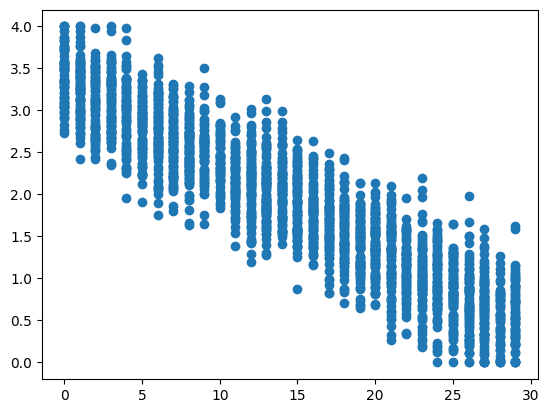

----------------------------------------------------------------------------------------------------
4.0 20.99215070643642
----------------------------------------------------------------------------------------------------
701


In [498]:
print(ds['Absences'].mean())

print('-'*100)

correlation = ds['Absences'].corr(ds['GPA'])
print(correlation)
plt.scatter(ds['Absences'], ds['GPA'])
plt.show()

print('-'*100)

highest_average_absences = ds.groupby(ds['GradeClass'])['Absences'].mean()
print(highest_average_absences.idxmax(), highest_average_absences.max())

print('-'*100)

print(ds[ds['Absences']> 20]['StudentID'].count())

### Tutoring
- Do students who receive tutoring have higher GPAs?
- What percentage of students receive tutoring?
- Are tutored students more likely to earn an A?

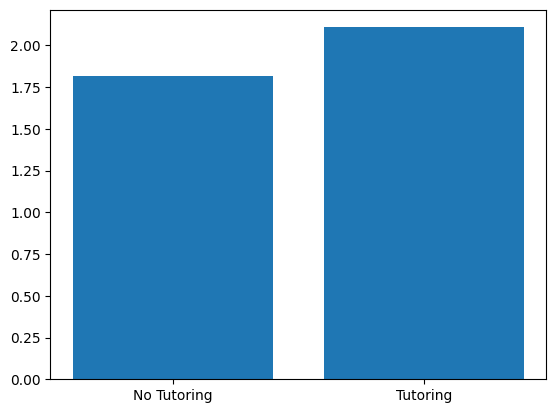

30.142140468227424
GradeClass      False     True 
Tutoring                       
0           98.084979  1.915021
1           93.758669  6.241331
0.11247414139028913


In [541]:
tutoring = ds.groupby('Tutoring')['GPA'].mean()
tutoring.index = ['No Tutoring', 'Tutoring']
plt.bar(tutoring.index, tutoring)
plt.show()

students = ds[ds['Tutoring'] == 1]['StudentID'].count()
print((students/ds.shape[0])*100)

Tutoring_A = pn.crosstab(ds['Tutoring'], ds['GradeClass'] == 0, normalize='index') * 100
print(Tutoring_A)
"""
we must look at the percentage of the tutored students of all students with the percentage of the Grade_A students of all students
"""
